In [1]:
from pathlib import Path
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Rectangle

sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges,
                  lon_c, lat_c, proj, style_map, cell_index)
from grid import nx as NX, ny as NY

In [2]:
DATA_DIR = Path("../data")      # data, tables, results (parquet, npz, csv, json)
FIG_DIR  = Path("../figures")   # all figures (png)

# Each notebook writes to its own subfolder; inputs come from earlier notebooks' folders
OUT_DIR = DATA_DIR / "07_enso_comparison"
FIG_OUT = FIG_DIR / "07_enso_comparison"
DIR_01  = DATA_DIR / "01_data_prep_roni_gdp"          # kuroshio_obs_clean, roni_phase
DIR_05  = DATA_DIR / "05_data_denial"                 # 05_summary (E95 curves, N*)
DIR_06  = DATA_DIR / "06_reliability"                 # product_velocity (region per cell)
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# --- Settings ---
WINDOW = ("2002-01", "2022-10")   # first and last month compared (both inclusive)
MIN_LAG = 12                      # smallest circular shift (months) in the permutation null
B = 3000                          # bootstrap replicates per cell and phase
SEED = 20261105                   # same base seed as 04 and 05
TARGET_CMPS = 10.0                # velocity precision target (cm/s)
SST_TARGET_C = 0.5                # SST precision target (°C)
MIN_DRIFTERS_TEST = 2             # drifters needed in each phase for a cell to be tested
MIN_VALID_PERMS = 100             # fewer valid permutations → p-value is NaN
ALPHA = 0.05                      # significance level (cell and field)

PHASES = ["El Niño", "non-El Niño"]                # Neutral and La Niña pooled as non-El Niño
SFX = {"El Niño": "en", "non-El Niño": "nonen"}    # column suffixes in the product tables
STREAM = {("vel", "El Niño"): 4, ("vel", "non-El Niño"): 5,   # bootstrap random streams
          ("sst", "El Niño"): 6, ("sst", "non-El Niño"): 7}   # (04 used 1–2, 05 used 3)
SEASONS = ["DJF", "MAM", "JJA", "SON"]
SEASON_OF_MONTH = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                   6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
N_CELLS = NY * NX
summary = {"window": list(WINDOW)}

### Data and window

In [4]:
obs = pd.read_parquet(DIR_01 / "kuroshio_obs_clean.parquet",
                      columns=["id", "lon", "lat", "time", "ve", "vn", "sst", "drogued", "enso"])

months = pd.period_range(WINDOW[0], WINDOW[1], freq="M")            # the compared months
in_window = obs["time"].between(months[0].start_time, months[-1].end_time)

def prepare(d, cols):
    """Window rows with cell, season and month index (0 = first month of WINDOW)."""
    d = d.loc[:, ["id", "lon", "lat", "time", "enso"] + cols].copy()
    d[cols] = d[cols].astype("float64")
    d["iy"], d["ix"] = cell_index(d)
    period = d["time"].dt.to_period("M")
    d["m"] = (period.dt.year - months[0].year) * 12 + (period.dt.month - months[0].month)
    d["season"] = d["time"].dt.month.map(SEASON_OF_MONTH)
    return d

vel_mask = obs["drogued"]                       # velocity: drogued hours only
sst_mask = obs["sst"].notna()                   # SST: every hour with a valid (flag-5) SST
vel = prepare(obs[vel_mask & in_window], ["ve", "vn"])
sst = prepare(obs[sst_mask & in_window], ["sst"])
sst["sst"] -= 273.15                            # K → °C
assert vel["m"].between(0, len(months) - 1).all() and sst["m"].between(0, len(months) - 1).all()

share_kept = {"velocity_drogued_hours": round(len(vel) / int(vel_mask.sum()), 4),
              "sst_hours": round(len(sst) / int(sst_mask.sum()), 4)}
summary["n_months"] = len(months)
summary["hours_in_window"] = {"velocity": len(vel), "sst": len(sst)}
summary["share_hours_kept"] = share_kept
print(f"{len(months)} months, {months[0]} to {months[-1]}")
print(f"velocity: {len(vel):,} of {int(vel_mask.sum()):,} drogued hours kept ({share_kept['velocity_drogued_hours']:.1%})")
print(f"SST:      {len(sst):,} of {int(sst_mask.sum()):,} SST hours kept ({share_kept['sst_hours']:.1%})")

250 months, 2002-01 to 2022-10
velocity: 2,121,271 of 2,135,791 drogued hours kept (99.3%)
SST:      4,379,625 of 4,395,082 SST hours kept (99.7%)


In [5]:
# --- Monthly phase series over the window ---
roni = pd.read_csv(DIR_01 / "roni_phase.csv", parse_dates=["time"])
phase_of_month = roni.set_index(roni["time"].dt.to_period("M"))["enso"].reindex(months)
assert phase_of_month.notna().all(), "RONI phase missing for a month in the window"
is_en = (phase_of_month == "El Niño").to_numpy()          # True = El Niño month

# The phase tagged in 01 should agree with the monthly series
for d in (vel, sst):
    assert ((d["enso"] == "El Niño") == is_en[d["m"].to_numpy()]).all()

# El Niño events = contiguous runs of El Niño months
starts = np.flatnonzero(is_en & ~np.r_[False, is_en[:-1]])
ends = np.flatnonzero(is_en & ~np.r_[is_en[1:], False])
events = pd.DataFrame({"start": months[starts].astype(str), "end": months[ends].astype(str),
                       "n_months": ends - starts + 1})
assert len(events) == 6, f"expected 6 El Niño events in the window, found {len(events)}"
print(events.to_string(index=False))
print(f"El Niño months: {is_en.sum()} of {len(months)}")

summary["el_nino_events_in_window"] = int(len(events))
summary["el_nino_events"] = events.to_dict("records")
summary["months_by_phase"] = {"El Niño": int(is_en.sum()), "non-El Niño": int((~is_en).sum())}

  start     end  n_months
2002-07 2003-01         7
2004-07 2005-01         7
2006-09 2007-01         5
2009-09 2010-03         7
2015-03 2016-04        14
2018-10 2019-04         7
El Niño months: 47 of 250


### Seasonal anomalies

Each observation minus the hour-weighted mean of its own cell and season over the window. This removes the seasonal cycle, so a phase sampled more in one season is not mistaken for an ENSO signal.

In [6]:
def add_anomalies(d, cols):
    """Anomaly = value − mean of its (cell, season); rows are hours, so the mean is hour-weighted."""
    clim = d.groupby(["iy", "ix", "season"])[cols].transform("mean")
    for c in cols:
        d[f"{c}_anom"] = d[c] - clim[c]

add_anomalies(vel, ["ve", "vn"])
add_anomalies(sst, ["sst"])

# Check: within each cell the anomalies average to ~0 (exactly 0 by construction, up to rounding)
anom_check = {}
for name, d, cols in [("velocity", vel, ["ve_anom", "vn_anom"]), ("sst", sst, ["sst_anom"])]:
    n_seasons = d.groupby(["iy", "ix"])["season"].nunique()
    cell_mean = d.groupby(["iy", "ix"])[cols].mean().abs().max(axis=1)
    four = n_seasons == 4
    anom_check[name] = {"cells": int(len(n_seasons)), "cells_missing_a_season": int((~four).sum()),
                        "max_abs_anom_mean_4_seasons": float(cell_mean[four].max()),
                        "max_abs_anom_mean_all_cells": float(cell_mean.max())}
    print(f"{name}: {len(n_seasons)} cells, {(~four).sum()} lack a season; "
          f"max |cell anomaly mean| = {cell_mean[four].max():.2e} (4 seasons), {cell_mean.max():.2e} (all)")
assert all(v["max_abs_anom_mean_all_cells"] < 1e-9 for v in anom_check.values())
summary["anomaly_check"] = anom_check

velocity: 595 cells, 65 lack a season; max |cell anomaly mean| = 3.77e-17 (4 seasons), 3.77e-17 (all)
sst: 618 cells, 61 lack a season; max |cell anomaly mean| = 2.79e-15 (4 seasons), 3.32e-15 (all)


### Month-level aggregate

One row per (cell, drifter, month). Relabelling months with a different phase only regroups these rows, so the permutation test never touches the hourly data.

In [7]:
def month_agg(d, cols):
    return (d.groupby(["iy", "ix", "id", "m"], sort=True)
              .agg(n=(cols[0], "size"), **{f"sum_{c}": (c, "sum") for c in cols})
              .reset_index())

vel_m = month_agg(vel, ["ve", "vn", "ve_anom", "vn_anom"])
sst_m = month_agg(sst, ["sst", "sst_anom"])
for t in (vel_m, sst_m):
    t["month"] = months[t["m"].to_numpy()].to_timestamp()                     # month start
    t["phase"] = np.where(is_en[t["m"].to_numpy()], "El Niño", "non-El Niño")  # observed phase

assert vel_m["n"].sum() == len(vel) and sst_m["n"].sum() == len(sst), "month aggregate lost hours"
vel_m.to_parquet(OUT_DIR / "vel_month_1deg.parquet", index=False)
sst_m.to_parquet(OUT_DIR / "sst_month_1deg.parquet", index=False)
print(f"velocity: {len(vel_m):,} rows, {vel_m['n'].sum():,} hours | SST: {len(sst_m):,} rows, {sst_m['n'].sum():,} hours")

velocity: 29,318 rows, 2,121,271 hours | SST: 60,397 rows, 4,379,625 hours


### Observed phase means and differences

In [8]:
full_index = pd.MultiIndex.from_product([range(NY), range(NX)], names=["iy", "ix"])

def phase_table(t, means, scale):
    """Per cell and phase: drifters, hours, hour-weighted means (× scale). Wide, full grid.
    means maps output name → sum column of the month table."""
    g = t.groupby(["iy", "ix", "phase"])
    out = g.agg(n_drifters=("id", "nunique"), n_hours=("n", "sum"))
    for name, col in means.items():
        out[name] = g[col].sum() / out["n_hours"] * scale
    out = out.unstack("phase")
    out.columns = [f"{c}_{SFX[p]}" for c, p in out.columns]
    out = out.reindex(full_index)
    for p in PHASES:
        for c in ["n_drifters", "n_hours"]:
            out[f"{c}_{SFX[p]}"] = out[f"{c}_{SFX[p]}"].fillna(0).astype("int64")
    return out

# Velocity (cm/s): absolute and anomaly means per phase
vp = phase_table(vel_m, {"mean_ve_cmps": "sum_ve", "mean_vn_cmps": "sum_vn",
                         "anom_ve_cmps": "sum_ve_anom", "anom_vn_cmps": "sum_vn_anom"}, 100)
for s in SFX.values():
    vp[f"mean_vector_speed_cmps_{s}"] = np.hypot(vp[f"mean_ve_cmps_{s}"], vp[f"mean_vn_cmps_{s}"])
vp["d_ve_cmps"] = vp["anom_ve_cmps_en"] - vp["anom_ve_cmps_nonen"]
vp["d_vn_cmps"] = vp["anom_vn_cmps_en"] - vp["anom_vn_cmps_nonen"]
vp["abs_du_cmps"] = np.hypot(vp["d_ve_cmps"], vp["d_vn_cmps"])
vp["tested"] = (vp["n_drifters_en"] >= MIN_DRIFTERS_TEST) & (vp["n_drifters_nonen"] >= MIN_DRIFTERS_TEST)

# SST (°C)
sp = phase_table(sst_m, {"mean_sst_c": "sum_sst", "anom_sst_c": "sum_sst_anom"}, 1)
sp["d_sst_c"] = sp["anom_sst_c_en"] - sp["anom_sst_c_nonen"]
sp["abs_d_sst_c"] = sp["d_sst_c"].abs()
sp["tested"] = (sp["n_drifters_en"] >= MIN_DRIFTERS_TEST) & (sp["n_drifters_nonen"] >= MIN_DRIFTERS_TEST)

for name, t in [("velocity", vp), ("SST", sp)]:
    has_both = (t["n_drifters_en"] > 0) & (t["n_drifters_nonen"] > 0)
    print(f"{name}: {((t['n_drifters_en'] + t['n_drifters_nonen']) > 0).sum()} cells with data, "
          f"{has_both.sum()} with both phases, {t['tested'].sum()} tested (≥{MIN_DRIFTERS_TEST} drifters in each)")
summary["cells_tested"] = {"velocity": int(vp["tested"].sum()), "sst": int(sp["tested"].sum())}

velocity: 595 cells with data, 550 with both phases, 493 tested (≥2 drifters in each)
SST: 618 cells with data, 580 with both phases, 559 tested (≥2 drifters in each)


### Per-phase bootstrap and reliability

Whole-drifter bootstrap of each phase's absolute mean, as in 04. A drifter's rows within one phase and cell are summed into one record.

In [9]:
def bootstrap_means(sums, hours, B, rng, batch=250):
    """Whole-drifter bootstrap of an hour-weighted mean (same as 04)."""
    sums = np.asarray(sums, dtype=np.float64)
    if sums.ndim == 1:
        sums = sums[:, None]
    hours = np.asarray(hours, dtype=np.float64)
    N = len(hours)
    assert N >= 2 and len(sums) == N and (hours > 0).all()
    draws = np.empty((B, sums.shape[1]), dtype=np.float64)
    for start in range(0, B, batch):
        stop = min(start + batch, B)
        ids = rng.integers(0, N, size=(stop - start, N))
        draws[start:stop] = sums[ids].sum(axis=1) / hours[ids].sum(axis=1)[:, None]
    return draws


def velocity_ci(sums, hours, mean, rng):
    """95% percentile CIs and U95 (cm/s) for one cell's mean current (same as 04)."""
    draws = bootstrap_means(sums, hours, B, rng) * 100
    lo, hi = np.quantile(draws, [0.025, 0.975], axis=0)
    out = {}
    for j, component in enumerate(["ve", "vn"]):
        out[f"{component}_ci_low_cmps"] = float(lo[j])
        out[f"{component}_ci_high_cmps"] = float(hi[j])
        out[f"{component}_ci_halfwidth_cmps"] = float((hi[j] - lo[j]) / 2)
    distance = np.linalg.norm(draws - mean[None, :] * 100, axis=1)
    out["U95_cmps"] = float(np.quantile(distance, 0.95))
    return out


def cell_rng(seed, iy, ix, stream):
    """Separate, reproducible random stream for each cell (streams 4–7 here)."""
    return np.random.default_rng(np.random.SeedSequence([seed, int(iy), int(ix), stream]))


def per_drifter(t, cols):
    """One record per (cell, phase, drifter): hours and sums within that phase."""
    return t.groupby(["iy", "ix", "phase", "id"], sort=True)[["n"] + cols].sum().reset_index()

t0 = time.perf_counter()
vel_d = per_drifter(vel_m, ["sum_ve", "sum_vn"])
rows = []
for (iy, ix, phase), g in vel_d.groupby(["iy", "ix", "phase"], sort=True):
    if len(g) < 2:
        continue
    sums, hours = g[["sum_ve", "sum_vn"]].to_numpy(), g["n"].to_numpy(dtype=np.float64)
    r = velocity_ci(sums, hours, sums.sum(axis=0) / hours.sum(), cell_rng(SEED, iy, ix, STREAM[("vel", phase)]))
    rows.append({"iy": iy, "ix": ix, "phase": phase, **r})
vel_boot = pd.DataFrame(rows).set_index(["iy", "ix", "phase"]).unstack("phase")
vel_boot.columns = [f"{c}_{SFX[p]}" for c, p in vel_boot.columns]
vp = vp.join(vel_boot)
for s in SFX.values():
    vp[f"snr_{s}"] = vp[f"mean_vector_speed_cmps_{s}"] / vp[f"U95_cmps_{s}"]

sst_d = per_drifter(sst_m, ["sum_sst"])
rows = []
for (iy, ix, phase), g in sst_d.groupby(["iy", "ix", "phase"], sort=True):
    if len(g) < 2:
        continue
    draws = bootstrap_means(g["sum_sst"].to_numpy(), g["n"].to_numpy(), B,
                            cell_rng(SEED, iy, ix, STREAM[("sst", phase)]))[:, 0]
    low, high = np.quantile(draws, [0.025, 0.975])
    rows.append({"iy": iy, "ix": ix, "phase": phase, "sst_ci_low_c": low, "sst_ci_high_c": high,
                 "sst_ci_halfwidth_c": (high - low) / 2})
sst_boot = pd.DataFrame(rows).set_index(["iy", "ix", "phase"]).unstack("phase")
sst_boot.columns = [f"{c}_{SFX[p]}" for c, p in sst_boot.columns]
sp = sp.join(sst_boot)
bootstrap_seconds = time.perf_counter() - t0
for name, bt, col in [("velocity", vel_boot, "U95_cmps"), ("SST", sst_boot, "sst_ci_halfwidth_c")]:
    print(f"{name} cells bootstrapped (≥2 drifters in the phase):",
          {p: int(bt[f"{col}_{s}"].notna().sum()) for p, s in SFX.items()})
print(f"bootstrap time: {bootstrap_seconds:.1f} s")

velocity cells bootstrapped (≥2 drifters in the phase): {'El Niño': 493, 'non-El Niño': 575}
SST cells bootstrapped (≥2 drifters in the phase): {'El Niño': 562, 'non-El Niño': 595}
bootstrap time: 2.6 s


In [10]:
# --- Region (full-record classification from 06) and N* (FPC-corrected, from 05) ---
s05 = json.loads((DIR_05 / "05_summary.json").read_text())
assert s05["primary"] == "fpc_corrected"
N_STAR = {r: int(v) for r, v in s05["N_star"].items()}

prod06 = pd.read_parquet(DIR_06 / "product_velocity_1deg.parquet").set_index(["iy", "ix"]).reindex(full_index)
assert (prod06["N_star"] == prod06["region"].map(N_STAR)).all(), "06 and 05 disagree on N*"
for t in (vp, sp):
    t["region"] = prod06["region"]
    t["N_star"] = prod06["N_star"]
    t["has_velocity_record"] = prod06["n_drifters"] > 0    # full-record velocity data (06)

# --- Achievable precision: refit log(E95) = a + b·log(k) to 05's FPC-corrected median curves ---
fits = {}
for region, curve in s05["median_E95_cmps"].items():
    k = np.array([int(x) for x in curve]); e95 = np.array(list(curve.values()))
    b, a = np.polyfit(np.log(k), np.log(e95), 1)
    n_star = int(np.ceil(np.exp((np.log(TARGET_CMPS) - a) / b)))
    fits[region] = {"intercept_a": round(float(a), 4), "slope_b": round(float(b), 4), "N_star_refit": n_star}
    assert n_star == N_STAR[region], f"refit N* {n_star} ≠ 05's {N_STAR[region]} ({region})"
    print(f"{region:>13}: a = {a:.3f}, b = {b:.3f} (05: {s05['slopes'][region]}), N* = {n_star} (05: {N_STAR[region]})")
summary["N_star"] = N_STAR
summary["achievable_precision_fit"] = fits

a_cell = vp["region"].map({r: f["intercept_a"] for r, f in fits.items()})
b_cell = vp["region"].map({r: f["slope_b"] for r, f in fits.items()})
for s in SFX.values():
    n = vp[f"n_drifters_{s}"]
    vp[f"achievable_E95_cmps_{s}"] = (np.exp(a_cell) * n.astype(float) ** b_cell).where(n > 0)
    vp[f"drifters_needed_{s}"] = (vp["N_star"] - n).clip(lower=0).where(vp["has_velocity_record"])
    vp[f"reliable_{s}"] = (n >= vp["N_star"]) & (vp[f"U95_cmps_{s}"] <= TARGET_CMPS)
    sp[f"reliable_{s}"] = sp[f"sst_ci_halfwidth_c_{s}"] <= SST_TARGET_C

for name, t in [("velocity", vp), ("SST", sp)]:
    print(f"{name} reliable cells:", {p: int(t[f'reliable_{s}'].sum()) for p, s in SFX.items()})

          jet: a = 4.703, b = -0.544 (05: -0.544), N* = 83 (05: 83)
recirculation: a = 4.238, b = -0.595 (05: -0.595), N* = 26 (05: 26)
velocity reliable cells: {'El Niño': 0, 'non-El Niño': 245}
SST reliable cells: {'El Niño': 18, 'non-El Niño': 147}


### Block-permutation null

The monthly phase series is shifted circularly by every lag from MIN_LAG to 250 − MIN_LAG months. Each shift keeps the length and spacing of the El Niño events but moves them to other years, so it breaks any link with the ocean while keeping the drifters, months and anomalies fixed.

In [11]:
lags = np.arange(MIN_LAG, len(months) - MIN_LAG + 1)
assert len(lags) == 227, len(lags)


def prepare_arrays(t, cols):
    """Arrays for regrouping the month table by (cell, phase) with np.bincount."""
    cell = (t["iy"] * NX + t["ix"]).to_numpy()
    cd = t.groupby(["iy", "ix", "id"], sort=True).ngroup().to_numpy()   # (cell, drifter) group
    cd_cell = np.zeros(cd.max() + 1, dtype=int)
    cd_cell[cd] = cell
    return {"cell": cell, "cd": cd, "cd_cell": cd_cell, "n_cd": len(cd_cell), "m": t["m"].to_numpy(),
            "n": t["n"].to_numpy(dtype=np.float64), "sums": t[cols].to_numpy(dtype=np.float64)}


def phase_difference(A, en_month, kind):
    """|Δ| of anomaly means (El Niño − non-El Niño) per cell, and whether both phases have enough drifters."""
    ph = (~en_month[A["m"]]).astype(int)                      # 0 = El Niño, 1 = non-El Niño
    key = A["cell"] * 2 + ph
    hours = np.bincount(key, A["n"], 2 * N_CELLS).reshape(N_CELLS, 2)
    sums = np.stack([np.bincount(key, A["sums"][:, j], 2 * N_CELLS) for j in range(A["sums"].shape[1])],
                    axis=-1).reshape(N_CELLS, 2, -1)
    present = np.bincount(A["cd"] * 2 + ph, minlength=2 * A["n_cd"]).reshape(-1, 2) > 0
    n_drifters = np.stack([np.bincount(A["cd_cell"], present[:, p], N_CELLS) for p in (0, 1)], axis=-1)
    with np.errstate(invalid="ignore", divide="ignore"):
        diff = sums[:, 0] / hours[:, 0, None] - sums[:, 1] / hours[:, 1, None]
    stat = np.hypot(diff[:, 0], diff[:, 1]) * 100 if kind == "vel" else np.abs(diff[:, 0])
    ok = (n_drifters >= MIN_DRIFTERS_TEST).all(axis=1)
    return np.where(ok, stat, np.nan), ok


def permutation_null(A, kind):
    D = np.full((len(lags), N_CELLS), np.nan)
    for i, lag in enumerate(lags):
        D[i], _ = phase_difference(A, np.roll(is_en, lag), kind)
    return D


arrays = {"vel": prepare_arrays(vel_m, ["sum_ve_anom", "sum_vn_anom"]),
          "sst": prepare_arrays(sst_m, ["sum_sst_anom"])}
observed = {"vel": vp["abs_du_cmps"].to_numpy(), "sst": sp["abs_d_sst_c"].to_numpy()}
tested = {"vel": vp["tested"].to_numpy(), "sst": sp["tested"].to_numpy()}

null, perm_seconds = {}, {}
for kind, A in arrays.items():
    # Lag 0 must reproduce the observed differences and tested cells from step 4
    d0, ok0 = phase_difference(A, is_en, kind)
    assert (ok0 == tested[kind]).all()
    assert np.allclose(d0[ok0], observed[kind][ok0], rtol=0, atol=1e-9)
    t0 = time.perf_counter()
    null[kind] = permutation_null(A, kind)
    perm_seconds[kind] = time.perf_counter() - t0
    print(f"{kind}: {len(lags)} permutations in {perm_seconds[kind]:.1f} s")
summary["n_permutations"] = int(len(lags))
summary["permutation_lags_months"] = [int(lags[0]), int(lags[-1])]

vel: 227 permutations in 0.2 s
sst: 227 permutations in 0.3 s


In [12]:
def cell_p_values(D, obs, tested):
    """p = (1 + valid perms with Δ ≥ observed) / (1 + valid perms); NaN if too few valid perms."""
    n_valid = (~np.isnan(D)).sum(axis=0)
    exceed = (D >= obs[None, :]).sum(axis=0)              # NaN compares False
    p = (1 + exceed) / (1 + n_valid)
    p = np.where(tested & (n_valid >= MIN_VALID_PERMS), p, np.nan)
    return p, n_valid


def field_significance(D, p_obs):
    """Null distribution of the number of significant cells: each permutation in turn plays
    'observed' and is ranked against the other valid permutations of the same cell."""
    use = ~np.isnan(p_obs)
    Du = D[:, use]
    valid = ~np.isnan(Du)
    n_valid = valid.sum(axis=0)
    ge = (Du[None, :, :] >= Du[:, None, :]).sum(axis=1)   # ge[j, c] = #k with D_k ≥ D_j (incl. j)
    p_null = ge / n_valid[None, :]                        # (1 + #others ≥) / (1 + #others)
    counts = ((p_null < ALPHA) & valid).sum(axis=1)
    observed_count = int((p_obs[use] < ALPHA).sum())
    p_field = (1 + (counts >= observed_count).sum()) / (1 + len(counts))
    return counts, observed_count, float(p_field), int(use.sum())


field = {}
for kind, t in [("vel", vp), ("sst", sp)]:
    p, n_valid = cell_p_values(null[kind], observed[kind], tested[kind])
    t["p_value"], t["n_valid_perms"] = p, n_valid
    counts, obs_count, p_field, n_with_p = field_significance(null[kind], p)
    field[kind] = {"counts": counts, "observed": obs_count, "p_field": p_field, "n_with_p": n_with_p}
    print(f"{kind}: {obs_count} of {n_with_p} cells with p < {ALPHA} "
          f"(expected under the null {ALPHA * n_with_p:.1f}; null median {np.median(counts):.0f}, "
          f"95th pct {np.percentile(counts, 95):.0f}); field p = {p_field:.3f}")

vel: 37 of 483 cells with p < 0.05 (expected under the null 24.2; null median 20, 95th pct 34); field p = 0.026
sst: 27 of 549 cells with p < 0.05 (expected under the null 27.5; null median 24, 95th pct 47); field p = 0.421


In [13]:
# --- Tested cells whose p-value is NaN (too few valid permutations) ---
nan_p = {}
for kind, t in [("vel", vp), ("sst", sp)]:
    bad = t[t["tested"] & t["p_value"].isna()]
    nan_p[kind] = bad
    print(f"{kind}: {len(bad)} tested cells with p = NaN (valid permutations < {MIN_VALID_PERMS})")
    if len(bad):
        show = bad.assign(lon=lon_c[bad.index.get_level_values('ix')], lat=lat_c[bad.index.get_level_values('iy')])
        print(show[["lon", "lat", "n_drifters_en", "n_drifters_nonen", "n_valid_perms"]].to_string(index=False))

vel: 10 tested cells with p = NaN (valid permutations < 100)
  lon  lat  n_drifters_en  n_drifters_nonen  n_valid_perms
119.5 16.5              3                 3             56
120.5 17.5              4                 2             49
124.5 28.5              3                 3             93
125.5 31.5              2                 3             60
126.5 31.5              3                 3             73
124.5 32.5              3                 4             87
125.5 32.5              3                 3             90
126.5 33.5              2                 5             94
128.5 37.5              2                 3             59
128.5 39.5              3                 4             73
sst: 10 tested cells with p = NaN (valid permutations < 100)
  lon  lat  n_drifters_en  n_drifters_nonen  n_valid_perms
120.5 17.5              5                 4             83
119.5 25.5              2                 5             87
121.5 28.5              2                 2         

### Flags and products

In [14]:
for t in (vp, sp):
    t["significant"] = t["p_value"] < ALPHA                    # NaN p → not significant
    t["robust"] = t["significant"] & t["reliable_en"] & t["reliable_nonen"]
    t["significant_nonEN_reliable"] = t["significant"] & t["reliable_nonen"]
    t["lon_center"] = lon_c[t.index.get_level_values("ix")]
    t["lat_center"] = lat_c[t.index.get_level_values("iy")]

per_phase_vel = ["n_drifters", "n_hours", "mean_ve_cmps", "mean_vn_cmps", "mean_vector_speed_cmps",
                 "ve_ci_low_cmps", "ve_ci_high_cmps", "ve_ci_halfwidth_cmps",
                 "vn_ci_low_cmps", "vn_ci_high_cmps", "vn_ci_halfwidth_cmps", "U95_cmps", "snr",
                 "reliable", "achievable_E95_cmps", "drifters_needed", "anom_ve_cmps", "anom_vn_cmps"]
per_phase_sst = ["n_drifters", "n_hours", "mean_sst_c", "sst_ci_low_c", "sst_ci_high_c",
                 "sst_ci_halfwidth_c", "reliable", "anom_sst_c"]
flags = ["p_value", "n_valid_perms", "tested", "significant", "robust", "significant_nonEN_reliable"]

vel_cols = (["lon_center", "lat_center", "region", "N_star"]
            + [f"{c}_{s}" for s in SFX.values() for c in per_phase_vel]
            + ["d_ve_cmps", "d_vn_cmps", "abs_du_cmps"] + flags)
sst_cols = (["lon_center", "lat_center", "region"]
            + [f"{c}_{s}" for s in SFX.values() for c in per_phase_sst]
            + ["d_sst_c", "abs_d_sst_c"] + flags)

product_vel = vp[vel_cols].reset_index()
product_sst = sp[sst_cols].reset_index()
assert len(product_vel) == len(product_sst) == N_CELLS
product_vel.to_parquet(OUT_DIR / "product_enso_velocity_1deg.parquet", index=False)
product_vel.to_csv(OUT_DIR / "product_enso_velocity_1deg.csv", index=False)
product_sst.to_parquet(OUT_DIR / "product_enso_sst_1deg.parquet", index=False)
product_sst.to_csv(OUT_DIR / "product_enso_sst_1deg.csv", index=False)

for name, t in [("velocity", vp), ("SST", sp)]:
    print(f"{name}: significant {int(t['significant'].sum())}, robust {int(t['robust'].sum())}, "
          f"significant & non-El Niño reliable {int(t['significant_nonEN_reliable'].sum())}")

velocity: significant 37, robust 0, significant & non-El Niño reliable 28
SST: significant 27, robust 2, significant & non-El Niño reliable 14


### Figures

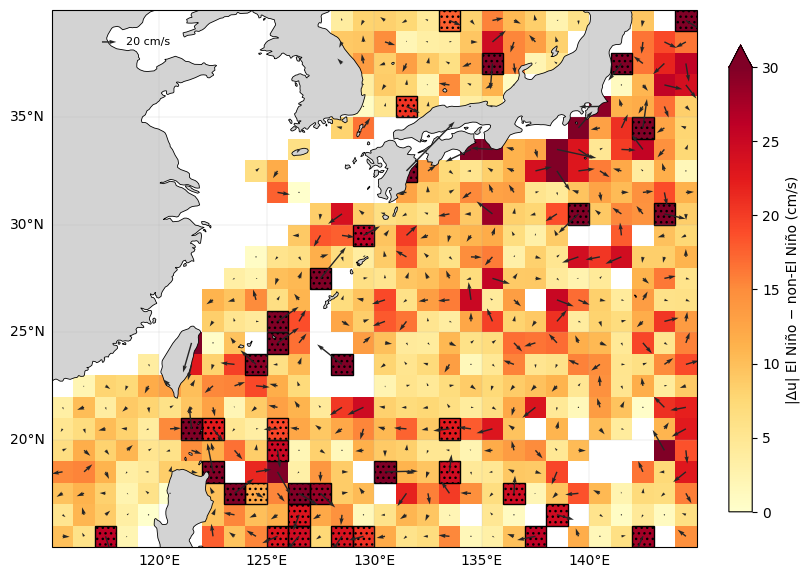

In [15]:
def grid_of(series):
    return series.reindex(full_index).to_numpy(dtype=float).reshape(NY, NX)


def mark_cells(ax, mask, hatch="...", color="k"):
    """Hatch and outline the given cells (boolean Series on the full grid)."""
    for iy, ix in mask.index[mask.fillna(False).to_numpy(dtype=bool)]:
        ax.add_patch(Rectangle((lon_edges[ix], lat_edges[iy]), RES, RES, fill=False, hatch=hatch,
                               edgecolor=color, lw=1.0, transform=proj, zorder=1.5))


# --- Velocity: |Δu| colour, Δu arrows, significant cells hatched ---
t = vp[vp["tested"]]
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, grid_of(t["abs_du_cmps"]), cmap="YlOrRd", vmin=0,
                  vmax=np.ceil(np.nanpercentile(t["abs_du_cmps"], 95)), transform=proj)
mark_cells(ax, vp["significant"])
q = ax.quiver(t["lon_center"], t["lat_center"], t["d_ve_cmps"], t["d_vn_cmps"], transform=proj,
              scale=900, scale_units="width", width=0.0022, color="0.15", zorder=4)
ax.quiverkey(q, 0.1, 0.94, 20, "20 cm/s", labelpos="E", coordinates="axes",
             fontproperties={"size": 8}, zorder=5)
style_map(ax)
fig.colorbar(m, ax=ax, shrink=0.8, extend="max", label="|Δu| El Niño − non-El Niño (cm/s)")
fig.savefig(FIG_OUT / "enso_velocity_difference_map.png", dpi=300, bbox_inches="tight")
plt.show()

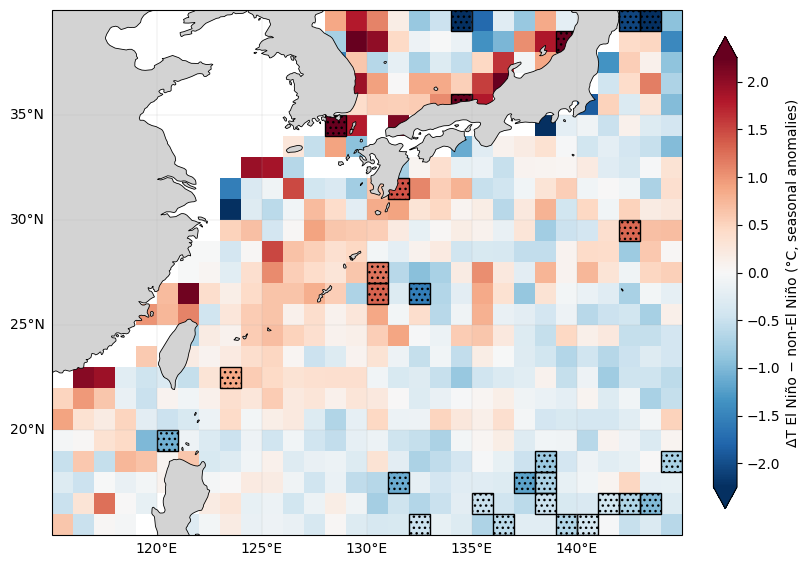

In [16]:
# --- SST: ΔT on a symmetric diverging scale, significant cells hatched ---
t = sp[sp["tested"]]
lim = np.ceil(np.nanpercentile(t["abs_d_sst_c"], 98) * 4) / 4        # round up to 0.25 °C
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained", subplot_kw={"projection": proj})
m = ax.pcolormesh(lon_edges, lat_edges, grid_of(t["d_sst_c"]), cmap="RdBu_r", vmin=-lim, vmax=lim,
                  transform=proj)
mark_cells(ax, sp["significant"])
style_map(ax)
fig.colorbar(m, ax=ax, shrink=0.8, extend="both", label="ΔT El Niño − non-El Niño (°C, seasonal anomalies)")
fig.savefig(FIG_OUT / "enso_sst_difference_map.png", dpi=300, bbox_inches="tight")
plt.show()

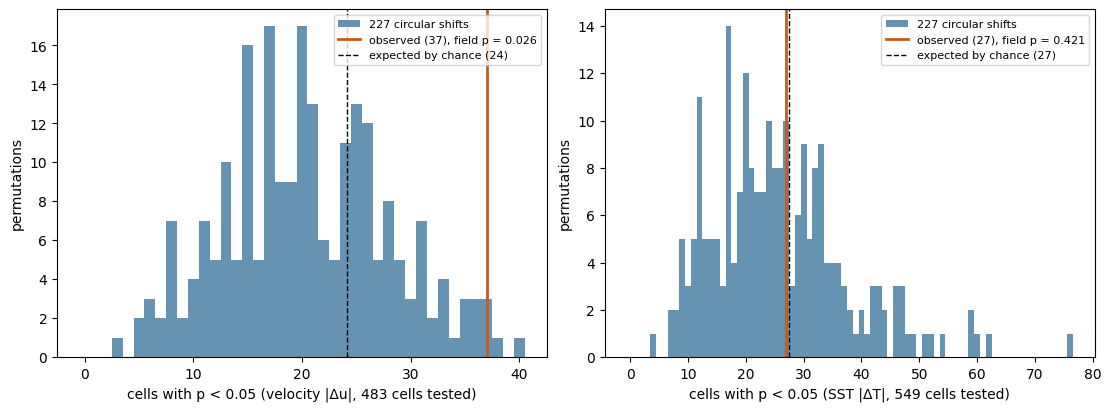

In [17]:
# --- Field significance: number of significant cells across permutations vs observed ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, (kind, label) in zip(axes, [("vel", "velocity |Δu|"), ("sst", "SST |ΔT|")]):
    f = field[kind]
    ax.hist(f["counts"], bins=np.arange(f["counts"].max() + 2) - 0.5, color="#4c80a5", alpha=0.85,
            label=f"{len(lags)} circular shifts")
    ax.axvline(f["observed"], color="#c55b19", lw=2, label=f"observed ({f['observed']}), field p = {f['p_field']:.3f}")
    ax.axvline(ALPHA * f["n_with_p"], color="k", ls="--", lw=1, label=f"expected by chance ({ALPHA * f['n_with_p']:.0f})")
    ax.set(xlabel=f"cells with p < {ALPHA} ({label}, {f['n_with_p']} cells tested)", ylabel="permutations")
    ax.legend(fontsize=8)
fig.savefig(FIG_OUT / "enso_field_significance.png", dpi=300, bbox_inches="tight")
plt.show()

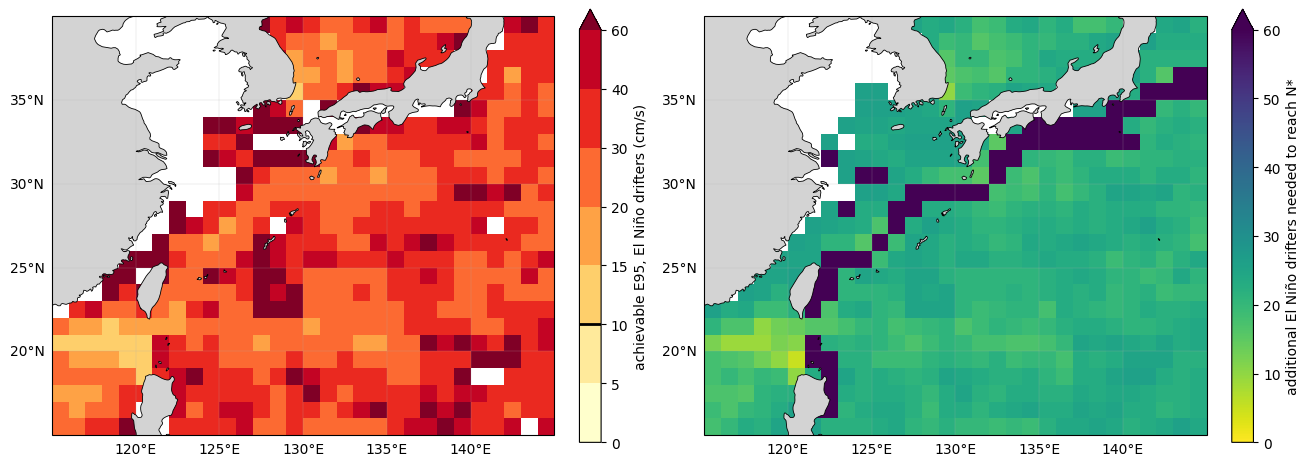

In [18]:
# --- El Niño achievable precision (fitted E95 at the El Niño drifter count) and drifters needed ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained", subplot_kw={"projection": proj})
levels = [0, 5, 10, 15, 20, 30, 40, 60]
norm = BoundaryNorm(levels, plt.get_cmap("YlOrRd").N, extend="max")
m1 = axes[0].pcolormesh(lon_edges, lat_edges, grid_of(vp["achievable_E95_cmps_en"]), cmap="YlOrRd",
                        norm=norm, transform=proj)
style_map(axes[0])
cb = fig.colorbar(m1, ax=axes[0], shrink=0.8, label="achievable E95, El Niño drifters (cm/s)")
cb.ax.axhline(TARGET_CMPS, color="k", lw=2)                           # the 10 cm/s target

m2 = axes[1].pcolormesh(lon_edges, lat_edges, grid_of(vp["drifters_needed_en"]), cmap="viridis_r",
                        vmin=0, vmax=60, transform=proj)
style_map(axes[1])
fig.colorbar(m2, ax=axes[1], shrink=0.8, extend="max", label="additional El Niño drifters needed to reach N*")
fig.savefig(FIG_OUT / "elnino_achievable_precision_map.png", dpi=300, bbox_inches="tight")
plt.show()

season         DJF    MAM    JJA    SON
phase                                  
El Niño      0.319  0.170  0.149  0.362
non-El Niño  0.232  0.271  0.276  0.222


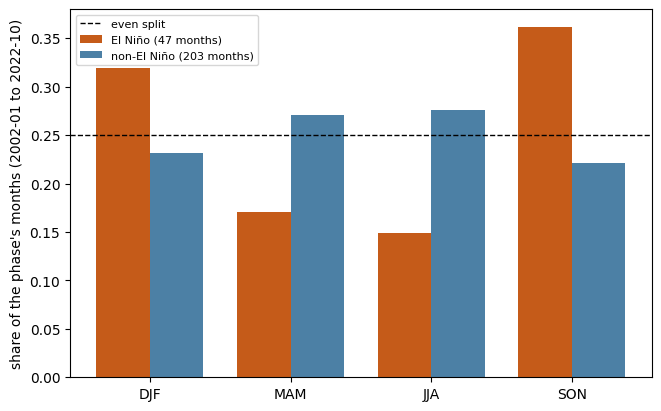

In [19]:
# --- Seasonal composition of El Niño and non-El Niño months in the window ---
season = pd.Series(months.month, index=months).map(SEASON_OF_MONTH)
composition = (pd.crosstab(np.where(is_en, "El Niño", "non-El Niño"), season.to_numpy(), normalize="index",
                           rownames=["phase"], colnames=["season"])
                 .reindex(index=PHASES, columns=SEASONS))
print(composition.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4), layout="constrained")
x = np.arange(len(SEASONS))
for i, (p, c) in enumerate(zip(PHASES, ["#c55b19", "#4c80a5"])):
    n = int(is_en.sum()) if p == "El Niño" else int((~is_en).sum())
    ax.bar(x + (i - 0.5) * 0.38, composition.loc[p], width=0.38, color=c, label=f"{p} ({n} months)")
ax.axhline(0.25, color="k", ls="--", lw=1, label="even split")
ax.set(xticks=x, xticklabels=SEASONS, ylabel=f"share of the phase's months ({WINDOW[0]} to {WINDOW[1]})")
ax.legend(fontsize=8)
fig.savefig(FIG_OUT / "elnino_months_by_season.png", dpi=300, bbox_inches="tight")
plt.show()

### Summary

In [20]:
def q(x, p):
    x = pd.Series(x).dropna()
    return round(float(np.quantile(x, p)), 3) if len(x) else None

def by_region(mask, t):
    return {r: int(mask[t["region"] == r].sum()) for r in ["jet", "recirculation"]}

summary["permutation_seconds"] = {k: round(v, 1) for k, v in perm_seconds.items()}
summary["bootstrap_seconds"] = round(bootstrap_seconds, 1)
summary["significance"] = {}
for kind, t, col in [("velocity", vp, "abs_du_cmps"), ("sst", sp, "abs_d_sst_c")]:
    f = field["vel" if kind == "velocity" else "sst"]
    tst, sig = t[t["tested"]], t[t["significant"]]
    summary["significance"][kind] = {
        "cells_tested": int(t["tested"].sum()),
        "cells_with_p": f["n_with_p"],
        "cells_p_nan": int((t["tested"] & t["p_value"].isna()).sum()),
        "significant": f["observed"],
        "expected_under_null": round(ALPHA * f["n_with_p"], 1),
        "null_count_median": float(np.median(f["counts"])),
        "null_count_95th_percentile": round(float(np.percentile(f["counts"], 95)), 1),
        "field_p": round(f["p_field"], 4),
        f"median_{col}_tested": q(tst[col], 0.5), f"p90_{col}_tested": q(tst[col], 0.9),
        f"median_{col}_significant": q(sig[col], 0.5), f"p90_{col}_significant": q(sig[col], 0.9),
        "robust": int(t["robust"].sum()),
        "significant_nonEN_reliable": int(t["significant_nonEN_reliable"].sum()),
    }
sig = sp[sp["significant"]]
summary["significance"]["sst"]["share_significant_dT_positive"] = round(float((sig["d_sst_c"] > 0).mean()), 4) if len(sig) else None
summary["significance"]["sst"]["share_significant_dT_negative"] = round(float((sig["d_sst_c"] < 0).mean()), 4) if len(sig) else None

summary["reliable_cells_by_phase"] = {
    kind: {p: {"total": int(t[f"reliable_{s}"].sum()), **by_region(t[f"reliable_{s}"], t)} for p, s in SFX.items()}
    for kind, t in [("velocity", vp), ("sst", sp)]}

en = vp["n_drifters_en"] > 0
summary["el_nino_precision"] = {
    "max_drifters_per_cell": int(vp["n_drifters_en"].max()),
    "cells_with_el_nino_velocity_data": int(en.sum()),
    "cells_el_nino_n_ge_N_star": int((vp["n_drifters_en"] >= vp["N_star"]).sum()),
    "median_achievable_E95_cmps": q(vp.loc[en, "achievable_E95_cmps_en"], 0.5),
    "median_achievable_E95_cmps_tested": q(vp.loc[vp["tested"], "achievable_E95_cmps_en"], 0.5),
    "median_drifters_needed_by_region": {r: q(vp.loc[en & (vp["region"] == r), "drifters_needed_en"], 0.5)
                                         for r in ["jet", "recirculation"]},
}
summary["seasonal_composition_of_months"] = {p: {s: round(float(v), 4) for s, v in composition.loc[p].items()}
                                             for p in PHASES}

(OUT_DIR / "07_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "window": [
    "2002-01",
    "2022-10"
  ],
  "n_months": 250,
  "hours_in_window": {
    "velocity": 2121271,
    "sst": 4379625
  },
  "share_hours_kept": {
    "velocity_drogued_hours": 0.9932,
    "sst_hours": 0.9965
  },
  "el_nino_events_in_window": 6,
  "el_nino_events": [
    {
      "start": "2002-07",
      "end": "2003-01",
      "n_months": 7
    },
    {
      "start": "2004-07",
      "end": "2005-01",
      "n_months": 7
    },
    {
      "start": "2006-09",
      "end": "2007-01",
      "n_months": 5
    },
    {
      "start": "2009-09",
      "end": "2010-03",
      "n_months": 7
    },
    {
      "start": "2015-03",
      "end": "2016-04",
      "n_months": 14
    },
    {
      "start": "2018-10",
      "end": "2019-04",
      "n_months": 7
    }
  ],
  "months_by_phase": {
    "El Niño": 47,
    "non-El Niño": 203
  },
  "anomaly_check": {
    "velocity": {
      "cells": 595,
      "cells_missing_a_season": 65,
      "max_abs_anom_mean_4_seasons": 3.765479